In [40]:
import polars as pl
import numpy as np
from datetime import date
import matplotlib.pyplot as plt
# Import requested libraries

In [3]:
df = pl.read_csv("../data/processed/online_retail_clean.csv", try_parse_dates = True)
# Read the dataset

In [4]:
df = df.with_columns(
    (pl.lit(date(2010, 12, 10)) - df["invoice_date"]).alias("recency")
)
# Calculate the recency of each customer's last purchase

In [5]:
frequency = df.group_by("customer_id").agg(
    pl.col("invoice").n_unique().alias("frequency")
)
# Calculate the number of unique invoices for each customer

In [6]:
df = df.with_columns(
    (pl.col("quantity") * pl.col("price")).alias("monetary")
)
# Calculate the monetary value of each transaction

In [7]:
customer_monetary = df.group_by("customer_id").agg(
    pl.col("monetary").sum().alias("total_monetary")
)
# Calculate the total monetary value for each customer

In [23]:
# Keep only positive-quantity transactions for RFM analysis.
df_rfm = df.filter(pl.col("quantity") > 0)

rfm = df_rfm.group_by("customer_id").agg(
    (date(2010, 12, 10) - pl.col("invoice_date").max()).dt.total_days().alias("recency"),
    pl.col("invoice").n_unique().alias("frequency"),
    pl.col("monetary").sum().alias("total_monetary")
)
rfm
# Calculate RFM metrics for each customer

customer_id,recency,frequency,total_monetary
i64,i64,u32,f64
13300,24,2,913.62
16325,60,9,3003.26
16846,213,2,628.09
18221,26,1,383.33
14095,358,1,2.95
…,…,…,…
15065,46,1,168.73
14612,51,1,877.7
16899,14,2,424.71


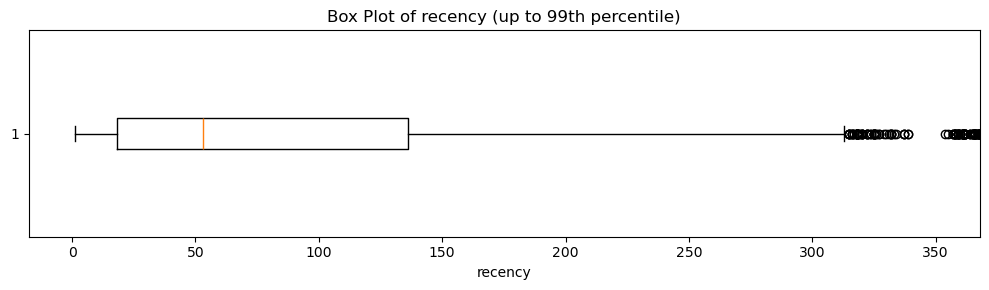

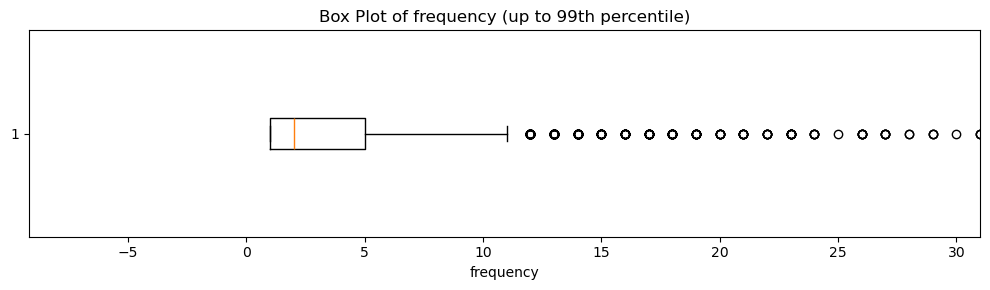

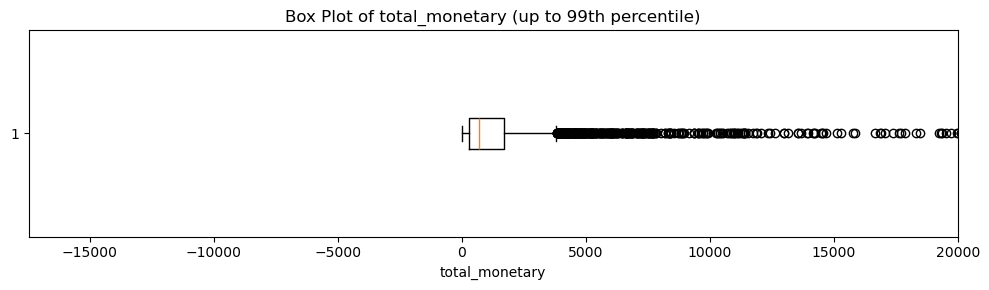

In [46]:
columns = ["recency","frequency", "total_monetary"]

for column in columns:
    values = rfm[column].to_numpy()

    # Set the upper limit at the 99th percentile for visualization
    upper_limit = np.percentile(values, 99)

    plt.figure(figsize = (10, 3))
    plt.boxplot(values, vert = False)
    plt.xlim(right = upper_limit)
    plt.title(f"Box Plot of {column} (up to 99th percentile)")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

In [45]:
rfm.select(["recency","frequency","total_monetary"]).describe()
# Inspect the distribution of RFM metrics

statistic,recency,frequency,total_monetary
str,f64,f64,f64
"""count""",4314.0,4314.0,4314.0
"""null_count""",0.0,0.0,0.0
"""mean""",91.269819,4.454103,2039.460766
"""std""",96.944304,8.168658,8909.797773
"""min""",1.0,1.0,0.0
"""25%""",18.0,1.0,307.1
"""50%""",53.0,2.0,701.61
"""75%""",136.0,5.0,1713.69
"""max""",374.0,205.0,349164.35
